# A6 — Regression Improvement

Goal: beat the A5b champion (`XGBoost_exp3_low_lr`, test R²≈0.764, CV mean R²≈0.715) using:
1. **XGBoost_exp3_low_lr** — old champion (replicated for direct comparison)
2. **RandomForest_tuned** — A5b second-best, also used as a stacking base learner
3. **CatBoost** — gradient boosting with built-in regularisation
4. **CatBoost_tuned** — CatBoost with best params from prior search (`l2_leaf_reg=1.0`)
5. **Stacking_RF_XGB_CatBoost** — RF + XGBoost + CatBoost → RidgeCV meta-learner
6. **Stacking_RF_XGB_CatBoost_tuned** — same stack but with CatBoost_tuned as the CatBoost base
7. **Lasso_poly2** — Lasso with degree-2 polynomial features and automatic alpha selection (LassoCV)

All models are evaluated with **5-fold CV** on the training set. Statistical significance vs the old champion is assessed with a paired t-test (α=0.05).

## Imports + paths + load data

In [2]:
import sys
print(sys.executable)

import warnings
warnings.filterwarnings('ignore', message='`artifact_path` is deprecated')
warnings.filterwarnings('ignore', category=FutureWarning, module='mlflow')

from urllib3.exceptions import InsecureRequestWarning
warnings.simplefilter('ignore', InsecureRequestWarning)

/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/bin/python


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Notebook location: ml/models/research/A6/Regression/
REG_PATH = Path('../../../data/raw/AimoScore_WeakLink_big_scores.xls')

df_reg = pd.read_excel(REG_PATH)
print('regression:', df_reg.shape)
display(df_reg.head(2))

regression: (2094, 43)


,AimoScore,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,...,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation,No_1_Time_Deviation,No_2_Time_Deviation,EstimatedScore,ID
0,0.323667,0.538020,0.815878,0.346724,0.382114,0.302248,0.947872,0.275945,0.52176,0.457198,...,0.656624,0.642276,0.552846,0.648972,0.578192,0.560019,0.821616,0.818747,0.209947,0003cdcc-86ed-494a-a3b5-90d09e96e06b.Kinect
1,0.323699,0.443807,0.306552,0.823529,0.188905,0.497370,0.140124,0.664275,0.52176,0.729316,...,0.721186,0.826399,0.805356,0.848876,0.889048,0.816834,0.307987,0.248207,0.457198,003115c4-bdb8-491c-b571-8fcebdecf8ed.Kinect


## Common utilities

In [4]:
from typing import Dict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def regression_metrics(y_true, y_pred) -> Dict[str, float]:
    return {
        'r2':   float(r2_score(y_true, y_pred)),
        'rmse': rmse(y_true, y_pred),
        'mae':  float(mean_absolute_error(y_true, y_pred)),
    }

## MLflow setup

In [5]:
import mlflow
from dotenv import load_dotenv, find_dotenv
from os import getenv

load_dotenv(find_dotenv())

tracking_uri = getenv('MLFLOW_TRACKING_URI')
if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    print('WARNING: MLFLOW_TRACKING_URI not set. MLflow will use its default local tracking location.')

EXPERIMENT_NAME = 'A6_regression_improvement'
mlflow.set_experiment(EXPERIMENT_NAME)

print('MLflow tracking URI:', mlflow.get_tracking_uri())
print('MLflow experiment:', EXPERIMENT_NAME)

MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A6_regression_improvement


## Dataset preparation

Identical 80/20 split and random seed as A5b so results are directly comparable.

In [6]:
from sklearn.model_selection import train_test_split

y = df_reg['AimoScore'].astype(float)
X = df_reg.drop(columns=['AimoScore', 'EstimatedScore', 'ID'], errors='ignore')
X = X.apply(pd.to_numeric, errors='coerce')

print('X:', X.shape, '  y:', y.shape)
print('Missing values in X:', int(X.isna().sum().sum()))
print(f'Target range: {y.min():.4f} – {y.max():.4f}')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)
print('Train:', X_train.shape, '  Test:', X_test.shape)

X: (2094, 40)   y: (2094,)
Missing values in X: 0
Target range: 0.0100 – 0.9940
Train: (1675, 40)   Test: (419, 40)


## Model helper

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

results: Dict[str, Dict] = {}


def train_and_log(name: str, pipeline, params: Dict) -> Dict[str, float]:
    """Fit pipeline, evaluate on train/test, log to MLflow, store in results dict."""
    pipeline.fit(X_train, y_train)

    train_m = regression_metrics(y_train, pipeline.predict(X_train))
    test_m  = regression_metrics(y_test,  pipeline.predict(X_test))

    with mlflow.start_run(run_name=name):
        mlflow.log_params(params)
        mlflow.log_params({
            'random_seed': RANDOM_SEED,
            'train_size':  int(X_train.shape[0]),
            'test_size':   int(X_test.shape[0]),
            'n_features':  int(X_train.shape[1]),
        })
        for k, v in train_m.items():
            mlflow.log_metric(f'train_{k}', v)
        for k, v in test_m.items():
            mlflow.log_metric(f'test_{k}', v)
        mlflow.sklearn.log_model(pipeline, name='model')

    results[name] = {'pipeline': pipeline, 'train': train_m, 'test': test_m}

    print(f'{name}')
    print(f"  Train  R\u00b2={train_m['r2']:.4f}  RMSE={train_m['rmse']:.4f}  MAE={train_m['mae']:.4f}")
    print(f"  Test   R\u00b2={test_m['r2']:.4f}  RMSE={test_m['rmse']:.4f}  MAE={test_m['mae']:.4f}")
    return test_m

---
## 1 — Old champion: XGBoost_exp3_low_lr

Replicated directly from A5b (same hyperparameters, same seed). This is the reference all challengers must beat.
- A5b test R² = 0.7638 | CV mean R² = 0.7152 (10-fold)

In [8]:
from xgboost import XGBRegressor

xgb_champion_params = {
    'model':            'XGBRegressor',
    'n_estimators':     1000,
    'learning_rate':    0.01,
    'max_depth':        6,
    'min_child_weight': 2,
    'subsample':        0.85,
    'colsample_bytree': 0.85,
    'reg_lambda':       1.0,
    'reg_alpha':        0.0,
    'objective':        'reg:squarederror',
    'tree_method':      'hist',
}

xgb_champion_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', XGBRegressor(
        n_estimators=1000,
        learning_rate=0.01,
        max_depth=6,
        min_child_weight=2,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        reg_alpha=0.0,
        objective='reg:squarederror',
        tree_method='hist',
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ))
])

train_and_log('XGBoost_exp3_low_lr', xgb_champion_pipe, xgb_champion_params)

2026/03/11 00:19:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run XGBoost_exp3_low_lr at: https://172.27.62.170:5001/#/experiments/16/runs/fedf7f02e4dc4c32bb74dd8bb41130c3
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
XGBoost_exp3_low_lr
  Train  R²=0.9867  RMSE=0.0270  MAE=0.0197
  Test   R²=0.7638  RMSE=0.1188  MAE=0.0855


{'r2': 0.7637730371644078,
 'rmse': 0.11876210776600227,
 'mae': 0.0855293562613857}

---
## 2 — Random Forest tuned

Second-best model from A5b (CV mean R²≈0.697). Included as a standalone challenger and as a base learner in the stacking ensemble.
- A5b test R² = 0.7423 | CV mean R² = 0.6968 (10-fold)

In [9]:
from sklearn.ensemble import RandomForestRegressor

rf_tuned_params = {
    'model':             'RandomForestRegressor',
    'n_estimators':      1000,
    'max_features':      0.5,
    'min_samples_leaf':  1,
    'min_samples_split': 5,
    'max_depth':         40,
    'max_samples':       None,
    'bootstrap':         True,
}

rf_tuned_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestRegressor(
        n_estimators=1000,
        max_features=0.5,
        min_samples_leaf=1,
        min_samples_split=5,
        max_depth=40,
        max_samples=None,
        bootstrap=True,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ))
])

train_and_log('RandomForest_tuned', rf_tuned_pipe, rf_tuned_params)

2026/03/11 00:19:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run RandomForest_tuned at: https://172.27.62.170:5001/#/experiments/16/runs/c078cb2dea5242f3abed0aa37f6f1a82
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
RandomForest_tuned
  Train  R²=0.9485  RMSE=0.0532  MAE=0.0384
  Test   R²=0.7423  RMSE=0.1240  MAE=0.0907


{'r2': 0.7422956068921296,
 'rmse': 0.12404351796770972,
 'mae': 0.09065065057682767}

---
## 3 — CatBoost

CatBoost uses symmetric (oblivious) decision trees and ordered boosting, which reduces prediction shift and improves generalisation on moderate-size tabular data. Its built-in L2 regularisation (`l2_leaf_reg`) and Bayesian bootstrap (`subsample`) make it robust without heavy hyperparameter tuning.

In [10]:
from catboost import CatBoostRegressor

catboost_params = {
    'model':             'CatBoostRegressor',
    'iterations':        1000,
    'learning_rate':     0.05,
    'depth':             6,
    'l2_leaf_reg':       3.0,
    'subsample':         0.85,
    'colsample_bylevel': 0.85,
    'min_data_in_leaf':  5,
    'loss_function':     'RMSE',
}

catboost_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=6,
        l2_leaf_reg=3.0,
        subsample=0.85,
        colsample_bylevel=0.85,
        min_data_in_leaf=5,
        loss_function='RMSE',
        random_seed=RANDOM_SEED,
        verbose=0,
    ))
])

train_and_log('CatBoost', catboost_pipe, catboost_params)

2026/03/11 00:20:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run CatBoost at: https://172.27.62.170:5001/#/experiments/16/runs/c99631d4f2dd49ef904a535abc909a09
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
CatBoost
  Train  R²=0.9883  RMSE=0.0254  MAE=0.0186
  Test   R²=0.7830  RMSE=0.1138  MAE=0.0833


{'r2': 0.7829556638203043,
 'rmse': 0.11383803543406386,
 'mae': 0.08331977594204683}

### 3b — CatBoost_tuned

Best configuration from a prior param search over `depth`, `l2_leaf_reg`, `learning_rate`, and `iterations`:
- `depth=6`, `l2_leaf_reg=1.0`, `learning_rate=0.05`, `iterations=1000`

Lowering `l2_leaf_reg` from 3.0 → 1.0 gave the best 5-fold CV R² (0.7198 vs 0.7183 for the base config).

In [11]:
catboost_tuned_params = {
    'model':             'CatBoostRegressor',
    'iterations':        1000,
    'learning_rate':     0.05,
    'depth':             6,
    'l2_leaf_reg':       1.0,
    'subsample':         0.85,
    'colsample_bylevel': 0.85,
    'min_data_in_leaf':  5,
    'loss_function':     'RMSE',
}

catboost_tuned_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=6,
        l2_leaf_reg=1.0,
        subsample=0.85,
        colsample_bylevel=0.85,
        min_data_in_leaf=5,
        loss_function='RMSE',
        random_seed=RANDOM_SEED,
        verbose=0,
    ))
])

train_and_log('CatBoost_tuned', catboost_tuned_pipe, catboost_tuned_params)

2026/03/11 00:20:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run CatBoost_tuned at: https://172.27.62.170:5001/#/experiments/16/runs/57994ea02b7d409182cde9b9687ef3ed
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
CatBoost_tuned
  Train  R²=0.9934  RMSE=0.0191  MAE=0.0141
  Test   R²=0.7717  RMSE=0.1167  MAE=0.0850


{'r2': 0.7717155147246211,
 'rmse': 0.11674851415556803,
 'mae': 0.08502490908074728}

---
## 4 — Stacking ensemble

Three diverse base learners feed their out-of-fold predictions to a RidgeCV meta-learner:
- **RF tuned** — bagging, MDI splits (high variance, low bias)
- **XGBoost_exp3_low_lr** — boosting, gradient-based (A5b champion)
- **CatBoost** — boosting, symmetric trees / ordered boosting

The `cv=5` inside `StackingRegressor` generates out-of-fold predictions so the meta-learner is never trained on in-sample base-learner outputs.

In [12]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.base import clone

stacking_estimators = [
    ('rf_tuned',  clone(rf_tuned_pipe)),
    ('xgb_champ', clone(xgb_champion_pipe)),
    ('catboost',  clone(catboost_pipe)),
]

stacking_pipe = StackingRegressor(
    estimators=stacking_estimators,
    final_estimator=RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0]),
    cv=5,
    n_jobs=-1,
)

stacking_params = {
    'model':         'StackingRegressor',
    'base_learners': 'RF_tuned + XGBoost_exp3_low_lr + CatBoost',
    'meta_learner':  'RidgeCV',
    'stacking_cv':   5,
    'passthrough':   False,
}

train_and_log('Stacking_RF_XGB_CatBoost', stacking_pipe, stacking_params)

2026/03/11 00:20:52 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run Stacking_RF_XGB_CatBoost at: https://172.27.62.170:5001/#/experiments/16/runs/be4570b178784e628b0d11530cced8b3
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
Stacking_RF_XGB_CatBoost
  Train  R²=0.9873  RMSE=0.0264  MAE=0.0204
  Test   R²=0.7806  RMSE=0.1145  MAE=0.0839


{'r2': 0.7805888064009262,
 'rmse': 0.11445705141150174,
 'mae': 0.08385082139480195}

### 4b — Stacking with CatBoost_tuned

Same ensemble as above but replacing the base CatBoost with the param-search winner (`CatBoost_tuned`). Everything else is identical.

In [13]:
stacking_tuned_estimators = [
    ('rf_tuned',       clone(rf_tuned_pipe)),
    ('xgb_champ',      clone(xgb_champion_pipe)),
    ('catboost_tuned', clone(catboost_tuned_pipe)),
]

stacking_tuned_pipe = StackingRegressor(
    estimators=stacking_tuned_estimators,
    final_estimator=RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0]),
    cv=5,
    n_jobs=-1,
)

stacking_tuned_params = {
    'model':         'StackingRegressor',
    'base_learners': 'RF_tuned + XGBoost_exp3_low_lr + CatBoost_tuned',
    'meta_learner':  'RidgeCV',
    'stacking_cv':   5,
    'passthrough':   False,
}

train_and_log('Stacking_RF_XGB_CatBoost_tuned', stacking_tuned_pipe, stacking_tuned_params)

2026/03/11 00:21:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run Stacking_RF_XGB_CatBoost_tuned at: https://172.27.62.170:5001/#/experiments/16/runs/867887d5ee4a40c184864e6f581ba313
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
Stacking_RF_XGB_CatBoost_tuned
  Train  R²=0.9899  RMSE=0.0235  MAE=0.0183
  Test   R²=0.7747  RMSE=0.1160  MAE=0.0848


{'r2': 0.7747446800459773,
 'rmse': 0.11597134445738544,
 'mae': 0.08479747354791879}

---
## 5 — Lasso with polynomial features (degree 2)

A linear model extended with all pairwise interactions and squared terms. With 40 original features, degree-2 expansion produces 860 features (40 linear + 820 interactions/squares). `LassoCV` automatically selects the regularisation strength `alpha` via 5-fold CV, driving irrelevant feature coefficients to zero. This tests whether the relationship between joint features and the target has exploitable polynomial structure not captured by the tree-based models.

In [14]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LassoCV

lasso_poly_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly',    PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler',  StandardScaler()),
    ('model',   LassoCV(cv=5, random_state=RANDOM_SEED, n_jobs=-1, max_iter=10000)),
])

lasso_poly_params = {
    'model':          'LassoCV',
    'poly_degree':    2,
    'include_bias':   False,
    'cv_folds_alpha': 5,
    'max_iter':       10000,
}

train_and_log('Lasso_poly2', lasso_poly_pipe, lasso_poly_params)

best_alpha = lasso_poly_pipe.named_steps['model'].alpha_
n_nonzero  = int(np.sum(lasso_poly_pipe.named_steps['model'].coef_ != 0))
n_total    = len(lasso_poly_pipe.named_steps['model'].coef_)
print(f'\nBest alpha (LassoCV): {best_alpha:.6f}')
print(f'Non-zero features: {n_nonzero} / {n_total}')

2026/03/11 00:22:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run Lasso_poly2 at: https://172.27.62.170:5001/#/experiments/16/runs/1e5e600691f743baae73968b0ec86cdf
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
Lasso_poly2
  Train  R²=0.7367  RMSE=0.1203  MAE=0.0894
  Test   R²=0.7175  RMSE=0.1299  MAE=0.0969

Best alpha (LassoCV): 0.000779
Non-zero features: 175 / 860


---
## 7 — Support Vector Regression (SVR)

SVR with an RBF kernel implicitly maps features into a high-dimensional space where a linear separator becomes non-linear in the original space. The key hyperparameters are:

- **C** — regularisation strength (higher = less regularisation, fits training data more closely)
- **gamma** — RBF kernel bandwidth (how far the influence of a single training sample reaches)
- **epsilon** — width of the "tube" around predictions where no penalty is applied

All three interact, so a small grid search is run first to find a good combination before logging the best model.

In [16]:
from sklearn.svm import SVR
from sklearn.model_selection import KFold, cross_val_score

svr_search_configs = [
    {'C': 1.0,   'gamma': 'scale', 'epsilon': 0.05},
    {'C': 10.0,  'gamma': 'scale', 'epsilon': 0.05},
    {'C': 100.0, 'gamma': 'scale', 'epsilon': 0.05},
    {'C': 10.0,  'gamma': 'auto',  'epsilon': 0.05},
    {'C': 10.0,  'gamma': 'scale', 'epsilon': 0.1},
    {'C': 100.0, 'gamma': 'auto',  'epsilon': 0.05},
]

kf_svr = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
svr_search_results = []

print(f"{'C':>8} {'gamma':>6} {'epsilon':>8}  {'CV R² mean':>10}  {'std':>6}")
print('-' * 50)

for cfg in svr_search_configs:
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
        ('model',   SVR(kernel='rbf', C=cfg['C'], gamma=cfg['gamma'], epsilon=cfg['epsilon'])),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=kf_svr, scoring='r2', n_jobs=-1)
    svr_search_results.append({**cfg, 'cv_r2_mean': scores.mean(), 'cv_r2_std': scores.std()})
    print(f"{cfg['C']:>8} {str(cfg['gamma']):>6} {cfg['epsilon']:>8}  {scores.mean():>10.4f}  {scores.std():>6.4f}")

svr_search_df = (
    pd.DataFrame(svr_search_results)
    .sort_values('cv_r2_mean', ascending=False)
    .reset_index(drop=True)
)
print('\nRanked:')
display(svr_search_df.style.format({'cv_r2_mean': '{:.4f}', 'cv_r2_std': '{:.4f}'}))

       C  gamma  epsilon  CV R² mean     std
--------------------------------------------------
     1.0  scale     0.05      0.6716  0.0230
    10.0  scale     0.05      0.6684  0.0250
   100.0  scale     0.05      0.6684  0.0250
    10.0   auto     0.05      0.6684  0.0250
    10.0  scale      0.1      0.6567  0.0231
   100.0   auto     0.05      0.6684  0.0250

Ranked:


,C,gamma,epsilon,cv_r2_mean,cv_r2_std
0,1.000000,scale,0.050000,0.6716,0.0230
1,10.000000,scale,0.050000,0.6684,0.0250
2,100.000000,scale,0.050000,0.6684,0.0250
3,10.000000,auto,0.050000,0.6684,0.0250
4,100.000000,auto,0.050000,0.6684,0.0250
5,10.000000,scale,0.100000,0.6567,0.0231


In [17]:
best_svr = svr_search_df.iloc[0].to_dict()
print(f"Best config: C={best_svr['C']}, gamma={best_svr['gamma']}, epsilon={best_svr['epsilon']}")
print(f"CV R²={best_svr['cv_r2_mean']:.4f} ± {best_svr['cv_r2_std']:.4f}")

svr_params = {
    'model':   'SVR',
    'kernel':  'rbf',
    'C':       float(best_svr['C']),
    'gamma':   str(best_svr['gamma']),
    'epsilon': float(best_svr['epsilon']),
}

svr_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
    ('model',   SVR(kernel='rbf',
                    C=float(best_svr['C']),
                    gamma=str(best_svr['gamma']),
                    epsilon=float(best_svr['epsilon']))),
])

train_and_log('SVR_rbf', svr_pipe, svr_params)

Best config: C=1.0, gamma=scale, epsilon=0.05
CV R²=0.6716 ± 0.0230


2026/03/11 00:24:16 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run SVR_rbf at: https://172.27.62.170:5001/#/experiments/16/runs/601611d5cf944e098910e9652c42a6b4
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
SVR_rbf
  Train  R²=0.9546  RMSE=0.0499  MAE=0.0434
  Test   R²=0.7512  RMSE=0.1219  MAE=0.0919


{'r2': 0.7511891191845433,
 'rmse': 0.12188432259633865,
 'mae': 0.0919447976236418}

---
## 6 — Historical baselines (A2 & A5 era)

Replicated here so they run on the same 80/20 split and 5-fold CV as all A6 models, making the progression comparison fair.

- **LinearRegression_A2** — linear regression with a single interaction term between the two features most correlated with the target, mirroring the A2 champion approach
- **GBR_A5** — sklearn `GradientBoostingRegressor`, representative of the A5 heterogeneous bootstrap ensemble (RF + GBR mean, test R²≈0.733)

In [18]:
from sklearn.linear_model import LinearRegression

# Replicate A2 approach: add interaction term between top-2 correlated features
corr_with_target = X_train.corrwith(y_train).abs().sort_values(ascending=False)
top2 = corr_with_target.head(2).index.tolist()
print(f'Top-2 features by |correlation| with target: {top2}')

interaction_col = f'{top2[0]}_x_{top2[1]}'
X_train_a2 = X_train.copy()
X_test_a2  = X_test.copy()
X_train_a2[interaction_col] = X_train[top2[0]] * X_train[top2[1]]
X_test_a2[interaction_col]  = X_test[top2[0]]  * X_test[top2[1]]

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

lr_a2_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model',   LinearRegression()),
])

lr_a2_params = {
    'model':            'LinearRegression',
    'assignment_era':   'A2',
    'interaction_term': interaction_col,
}

# train_and_log uses X_train/X_test — temporarily train on augmented data
lr_a2_pipe.fit(X_train_a2, y_train)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import mlflow

train_m = regression_metrics(y_train, lr_a2_pipe.predict(X_train_a2))
test_m  = regression_metrics(y_test,  lr_a2_pipe.predict(X_test_a2))
with mlflow.start_run(run_name='LinearRegression_A2'):
    mlflow.log_params({**lr_a2_params, 'random_seed': RANDOM_SEED,
                       'train_size': int(X_train.shape[0]), 'test_size': int(X_test.shape[0]),
                       'n_features': int(X_train_a2.shape[1])})
    for k, v in train_m.items(): mlflow.log_metric(f'train_{k}', v)
    for k, v in test_m.items():  mlflow.log_metric(f'test_{k}', v)
results['LinearRegression_A2'] = {'pipeline': lr_a2_pipe, 'train': train_m, 'test': test_m}
print('LinearRegression_A2')
print(f"  Train  R²={train_m['r2']:.4f}  RMSE={train_m['rmse']:.4f}  MAE={train_m['mae']:.4f}")
print(f"  Test   R²={test_m['r2']:.4f}  RMSE={test_m['rmse']:.4f}  MAE={test_m['mae']:.4f}")

Top-2 features by |correlation| with target: ['No_12_NASM_Deviation', 'No_11_NASM_Deviation']
🏃 View run LinearRegression_A2 at: https://172.27.62.170:5001/#/experiments/16/runs/d484f8b58a1d44b191f4b9676efda405
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
LinearRegression_A2
  Train  R²=0.6157  RMSE=0.1453  MAE=0.1119
  Test   R²=0.6412  RMSE=0.1464  MAE=0.1112


In [19]:
from sklearn.ensemble import GradientBoostingRegressor

gbr_a5_params = {
    'model':            'GradientBoostingRegressor',
    'assignment_era':   'A5',
    'n_estimators':     500,
    'learning_rate':    0.05,
    'max_depth':        4,
    'subsample':        0.8,
    'min_samples_leaf': 5,
}

gbr_a5_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        min_samples_leaf=5,
        random_state=RANDOM_SEED,
    )),
])

train_and_log('GBR_A5', gbr_a5_pipe, gbr_a5_params)

2026/03/11 00:24:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run GBR_A5 at: https://172.27.62.170:5001/#/experiments/16/runs/cbc99e6957e643069cc59b9041ee013f
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
GBR_A5
  Train  R²=0.9780  RMSE=0.0348  MAE=0.0254
  Test   R²=0.7594  RMSE=0.1199  MAE=0.0864


{'r2': 0.7593549123046479,
 'rmse': 0.11986755973191268,
 'mae': 0.08644845010870227}

---
## Results comparison

In [20]:
rows = []
for name, info in results.items():
    rows.append({
        'model':      name,
        'train_r2':   info['train']['r2'],
        'train_rmse': info['train']['rmse'],
        'train_mae':  info['train']['mae'],
        'test_r2':    info['test']['r2'],
        'test_rmse':  info['test']['rmse'],
        'test_mae':   info['test']['mae'],
    })

comparison = (
    pd.DataFrame(rows)
    .sort_values('test_r2', ascending=False)
    .reset_index(drop=True)
)

display(
    comparison.style.format({
        'train_r2': '{:.4f}', 'train_rmse': '{:.4f}', 'train_mae': '{:.4f}',
        'test_r2':  '{:.4f}', 'test_rmse':  '{:.4f}', 'test_mae':  '{:.4f}',
    }).background_gradient(subset=['test_r2'], cmap='RdYlGn')
)

best = comparison.iloc[0]
print(f"\nBest model: {best['model']}")
print(f"  Test R\u00b2={best['test_r2']:.4f}  RMSE={best['test_rmse']:.4f}  MAE={best['test_mae']:.4f}")

,model,train_r2,train_rmse,train_mae,test_r2,test_rmse,test_mae
0,CatBoost,0.9883,0.0254,0.0186,0.7830,0.1138,0.0833
1,Stacking_RF_XGB_CatBoost,0.9873,0.0264,0.0204,0.7806,0.1145,0.0839
2,Stacking_RF_XGB_CatBoost_tuned,0.9899,0.0235,0.0183,0.7747,0.1160,0.0848
3,CatBoost_tuned,0.9934,0.0191,0.0141,0.7717,0.1167,0.0850
4,XGBoost_exp3_low_lr,0.9867,0.0270,0.0197,0.7638,0.1188,0.0855
5,GBR_A5,0.9780,0.0348,0.0254,0.7594,0.1199,0.0864
6,SVR_rbf,0.9546,0.0499,0.0434,0.7512,0.1219,0.0919
7,RandomForest_tuned,0.9485,0.0532,0.0384,0.7423,0.1240,0.0907
8,Lasso_poly2,0.7367,0.1203,0.0894,0.7175,0.1299,0.0969
9,LinearRegression_A2,0.6157,0.1453,0.1119,0.6412,0.1464,0.1112



Best model: CatBoost
  Test R²=0.7830  RMSE=0.1138  MAE=0.0833


### Actual vs Predicted — best model

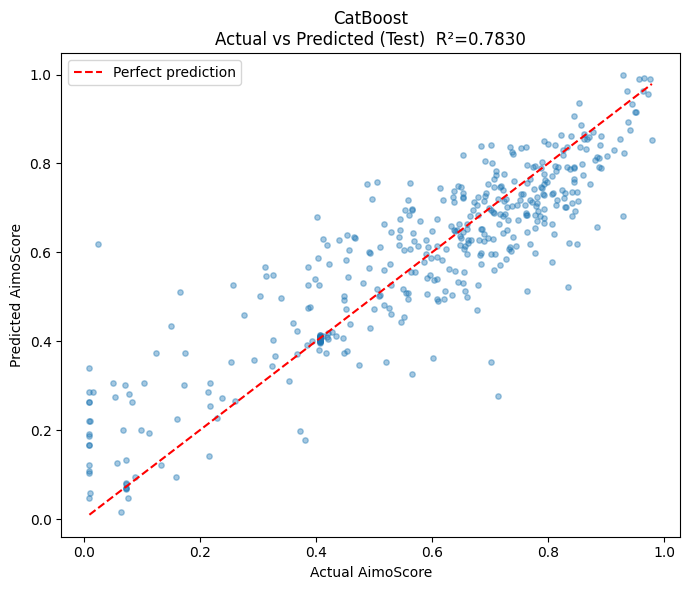

In [21]:
best_name = comparison.iloc[0]['model']
best_pipe = results[best_name]['pipeline']
y_pred_best = best_pipe.predict(X_test)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_best, alpha=0.4, s=15)
lo, hi = float(y_test.min()), float(y_test.max())
ax.plot([lo, hi], [lo, hi], 'r--', label='Perfect prediction')
ax.set_xlabel('Actual AimoScore')
ax.set_ylabel('Predicted AimoScore')
test_r2 = results[best_name]['test']['r2']
ax.set_title(f"{best_name}\nActual vs Predicted (Test)  R\u00b2={test_r2:.4f}")
ax.legend()
plt.tight_layout()
plt.show()

---
## 5-fold cross-validation

All models are evaluated on identical folds (`KFold(n_splits=5, shuffle=True, random_state=42)`). Shared folds make per-fold R² scores paired — which is required for a valid paired t-test below.

The reference for t-tests is the old A5b champion (`XGBoost_exp3_low_lr`).

In [38]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone

CV_FOLDS = 5
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)

# LinearRegression_A2 needs a pipeline that adds the interaction term internally
def add_interaction(X):
    X = X.copy()
    X[interaction_col] = X[top2[0]] * X[top2[1]]
    return X

lr_a2_cv_pipe = Pipeline([
    ('interaction', FunctionTransformer(add_interaction)),
    ('imputer',     SimpleImputer(strategy='median')),
    ('model',       LinearRegression()),
])

cv_pipelines = {
    'LinearRegression_A2':            lr_a2_cv_pipe,
    'GBR_A5':                         gbr_a5_pipe,
    'XGBoost_exp3_low_lr':            xgb_champion_pipe,
    # 'RandomForest_tuned':             rf_tuned_pipe,
    # 'CatBoost':                       catboost_pipe,
    # 'CatBoost_tuned':                 catboost_tuned_pipe,
    # 'Stacking_RF_XGB_CatBoost':       stacking_pipe,
    'Stacking_RF_XGB_CatBoost_tuned': stacking_tuned_pipe,
    # 'Lasso_poly2':                    lasso_poly_pipe,
    # 'SVR_rbf':                        svr_pipe,
}

cv_scores: Dict[str, np.ndarray] = {}

for name, pipe in cv_pipelines.items():
    scores = cross_val_score(
        clone(pipe),
        X_train, y_train,
        cv=kf,
        scoring='r2',
        n_jobs=-1,
    )
    cv_scores[name] = scores
    print(f'{name}')
    print(f"  Fold R²: {[f'{s:.4f}' for s in scores]}")
    print(f'  Mean={scores.mean():.4f}  Std={scores.std():.4f}\n')

LinearRegression_A2
  Fold R²: ['0.6028', '0.6412', '0.5746', '0.5746', '0.5818']
  Mean=0.5950  Std=0.0253

GBR_A5
  Fold R²: ['0.7370', '0.7314', '0.6759', '0.7036', '0.6829']
  Mean=0.7062  Std=0.0247

XGBoost_exp3_low_lr
  Fold R²: ['0.7366', '0.7529', '0.7007', '0.7188', '0.6894']
  Mean=0.7197  Std=0.0231

Stacking_RF_XGB_CatBoost_tuned
  Fold R²: ['0.7436', '0.7604', '0.7066', '0.7310', '0.6936']
  Mean=0.7270  Std=0.0242



### CV summary table

In [39]:
cv_summary = pd.DataFrame({
    name: {'cv_r2_mean': scores.mean(), 'cv_r2_std': scores.std()}
    for name, scores in cv_scores.items()
}).T.sort_values('cv_r2_mean', ascending=False).reset_index(names='model')

display(
    cv_summary.style.format({'cv_r2_mean': '{:.4f}', 'cv_r2_std': '{:.4f}'})
    .background_gradient(subset=['cv_r2_mean'], cmap='RdYlGn')
)

# Log CV metrics to each model's MLflow run
for name, scores in cv_scores.items():
    runs = mlflow.search_runs(
        experiment_names=[EXPERIMENT_NAME],
        filter_string=f"run_name = '{name}'",
    )
    if runs.empty:
        print(f"WARNING: no MLflow run found for '{name}', skipping CV logging")
        continue
    run_id = runs.iloc[0]['run_id']
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metric('cv_r2_mean', float(scores.mean()))
        mlflow.log_metric('cv_r2_std',  float(scores.std()))

print('CV R\u00b2 logged to MLflow runs.')

,model,cv_r2_mean,cv_r2_std
0,Stacking_RF_XGB_CatBoost_tuned,0.7270,0.0242
1,XGBoost_exp3_low_lr,0.7197,0.0231
2,GBR_A5,0.7062,0.0247
3,LinearRegression_A2,0.5950,0.0253


🏃 View run LinearRegression_A2 at: https://172.27.62.170:5001/#/experiments/16/runs/d484f8b58a1d44b191f4b9676efda405
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
🏃 View run GBR_A5 at: https://172.27.62.170:5001/#/experiments/16/runs/cbc99e6957e643069cc59b9041ee013f
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
🏃 View run XGBoost_exp3_low_lr at: https://172.27.62.170:5001/#/experiments/16/runs/fedf7f02e4dc4c32bb74dd8bb41130c3
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
🏃 View run Stacking_RF_XGB_CatBoost_tuned at: https://172.27.62.170:5001/#/experiments/16/runs/867887d5ee4a40c184864e6f581ba313
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
CV R² logged to MLflow runs.


### CV R² box plot

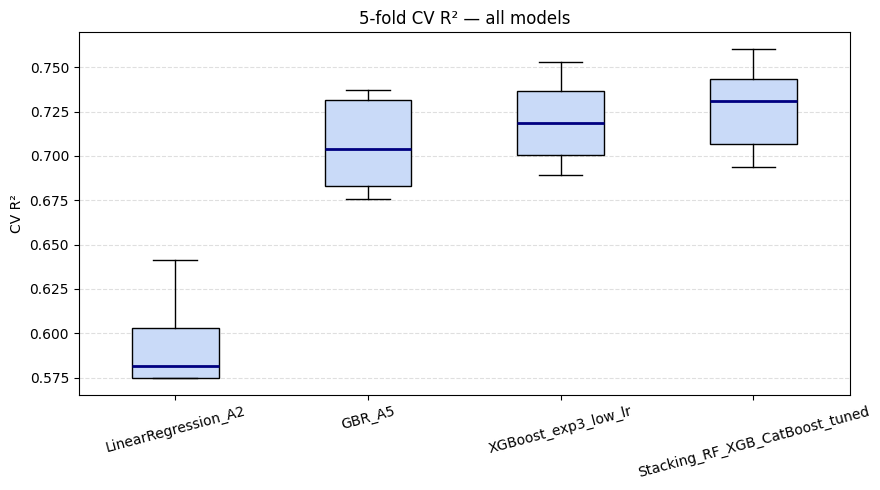

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))

names  = list(cv_scores.keys())
values = [cv_scores[n] for n in names]

ax.boxplot(values, tick_labels=names, patch_artist=True,
           boxprops=dict(facecolor='#c9daf8'),
           medianprops=dict(color='navy', linewidth=2))
ax.set_ylabel('CV R\u00b2')
ax.set_title('5-fold CV R\u00b2 — all models')
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### CV R² fitted Gaussians

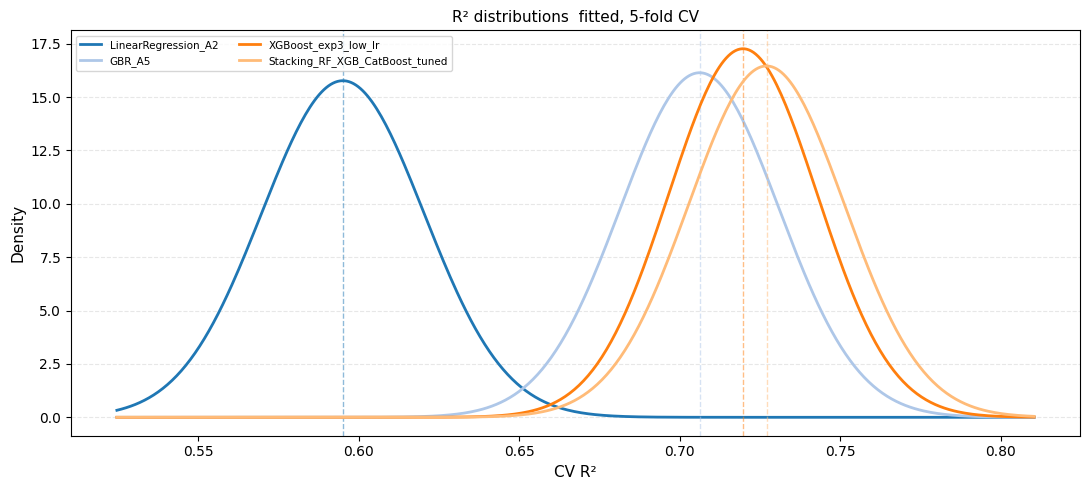

In [47]:
from scipy.stats import norm

palette = plt.cm.tab20.colors  # 20 distinct colours

x_min = min(s.min() for s in cv_scores.values()) - 0.05
x_max = max(s.max() for s in cv_scores.values()) + 0.05
x_grid = np.linspace(x_min, x_max, 400)

fig, ax = plt.subplots(figsize=(11, 5))
for (name, scores), color in zip(cv_scores.items(), palette):
    mu, sigma = scores.mean(), scores.std()
    ax.plot(x_grid, norm.pdf(x_grid, mu, sigma), color=color, linewidth=2.0, label=name)
    ax.axvline(mu, color=color, linewidth=1, linestyle='--', alpha=0.5)

ax.set_xlabel('CV R²', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('R² distributions  fitted, 5-fold CV', fontsize=11)
ax.legend(fontsize=7.5, ncol=2)
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

---
## Statistical significance — paired t-test vs old champion

Each challenger's per-fold CV R² scores are compared against `XGBoost_exp3_low_lr` using a two-sided paired t-test. Because all models share identical folds, the fold index acts as a blocking factor — the paired test is more sensitive than an independent-samples test.

- H₀: mean CV R² of challenger = mean CV R² of champion
- α = 0.05

In [42]:
from scipy.stats import ttest_rel

ALPHA     = 0.05
REFERENCE = 'XGBoost_exp3_low_lr'
ref_scores = cv_scores[REFERENCE]

print(f"Reference: {REFERENCE}  mean R\u00b2={ref_scores.mean():.4f}\n")
print(f"{'Challenger':<30s} {'mean diff':>10s} {'t-stat':>8s} {'p-value':>10s}  {'significant?':>14s}")
print('-' * 80)

ttest_rows = []
for name, scores in cv_scores.items():
    if name == REFERENCE:
        continue
    t_stat, p_val = ttest_rel(scores, ref_scores)
    mean_diff   = scores.mean() - ref_scores.mean()
    significant = p_val < ALPHA
    marker = '\u2713  (p < 0.05)' if significant else '\u2717  (not sig.)'
    print(f"{name:<30s} {mean_diff:>+10.4f} {t_stat:>8.3f} {p_val:>10.4f}  {marker:>14s}")
    ttest_rows.append({
        'challenger':          name,
        'challenger_mean_r2':  float(scores.mean()),
        'reference_mean_r2':   float(ref_scores.mean()),
        'mean_diff':           float(mean_diff),
        't_stat':              float(t_stat),
        'p_value':             float(p_val),
        'significant_at_0.05': significant,
    })

Reference: XGBoost_exp3_low_lr  mean R²=0.7197

Challenger                      mean diff   t-stat    p-value    significant?
--------------------------------------------------------------------------------
LinearRegression_A2               -0.1247  -18.350     0.0001   ✓  (p < 0.05)
GBR_A5                            -0.0135   -2.901     0.0441   ✓  (p < 0.05)
Stacking_RF_XGB_CatBoost_tuned    +0.0073    5.526     0.0052   ✓  (p < 0.05)


In [43]:
ttest_df = (
    pd.DataFrame(ttest_rows)
    .sort_values('mean_diff', ascending=False)
    .reset_index(drop=True)
)

display(
    ttest_df.style.format({
        'challenger_mean_r2': '{:.4f}',
        'reference_mean_r2':  '{:.4f}',
        'mean_diff':          '{:+.4f}',
        't_stat':             '{:.3f}',
        'p_value':            '{:.4f}',
    }).background_gradient(subset=['mean_diff'], cmap='RdYlGn')
)

,challenger,challenger_mean_r2,reference_mean_r2,mean_diff,t_stat,p_value,significant_at_0.05
0,Stacking_RF_XGB_CatBoost_tuned,0.7270,0.7197,+0.0073,5.526,0.0052,True
1,GBR_A5,0.7062,0.7197,-0.0135,-2.901,0.0441,True
2,LinearRegression_A2,0.5950,0.7197,-0.1247,-18.350,0.0001,True


In [44]:
with mlflow.start_run(run_name='ttest_summary'):
    mlflow.log_param('reference_model', REFERENCE)
    mlflow.log_param('cv_folds', CV_FOLDS)
    mlflow.log_param('alpha', ALPHA)
    mlflow.log_metric('reference_cv_r2_mean', float(ref_scores.mean()))
    mlflow.log_metric('reference_cv_r2_std',  float(ref_scores.std()))
    for row in ttest_rows:
        tag = row['challenger'].replace(' ', '_')
        mlflow.log_metric(f"ttest_pvalue_{tag}",    row['p_value'])
        mlflow.log_metric(f"ttest_mean_diff_{tag}", row['mean_diff'])

print('t-test summary logged to MLflow.')

🏃 View run ttest_summary at: https://172.27.62.170:5001/#/experiments/16/runs/1ebba5cb167241889fc1067413c203c2
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/16
t-test summary logged to MLflow.


---
## Assignment progression — 5-fold CV R²

Best model per assignment era, all evaluated on the same 5-fold CV and 80/20 split.

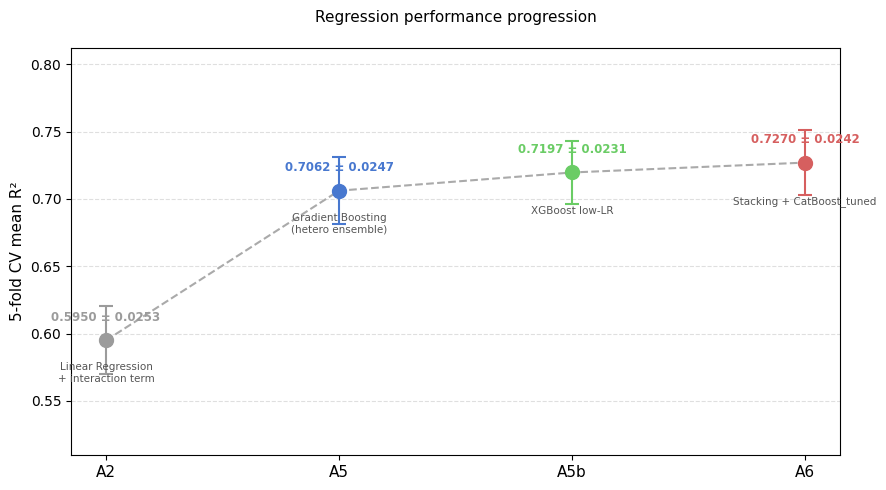

Saved: regression_progression.png


In [45]:
# One entry per assignment era: (x-label, cv_scores key, description)
progression_map = [
    ('A2',  'LinearRegression_A2',            'Linear Regression\n+ interaction term'),
    ('A5',  'GBR_A5',                         'Gradient Boosting\n(hetero ensemble)'),
    ('A5b', 'XGBoost_exp3_low_lr',            'XGBoost low-LR'),
    ('A6',  'Stacking_RF_XGB_CatBoost_tuned', 'Stacking + CatBoost_tuned'),
]

labels  = [p[0] for p in progression_map]
keys    = [p[1] for p in progression_map]
descs   = [p[2] for p in progression_map]
means   = [cv_scores[k].mean() for k in keys]
stds    = [cv_scores[k].std()  for k in keys]

colors  = ['#9b9b9b', '#4878cf', '#6acc65', '#d65f5f']

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(labels, means, color='#aaa', linewidth=1.5, linestyle='--', zorder=1)

for i, (label, mean, std, color, desc) in enumerate(zip(labels, means, stds, colors, descs)):
    ax.errorbar(label, mean, yerr=std, fmt='o', color=color,
                markersize=10, capsize=5, capthick=1.5, elinewidth=1.5, zorder=3)
    ax.annotate(
        f'{mean:.4f} ± {std:.4f}',
        xy=(label, mean), xytext=(0, 14), textcoords='offset points',
        ha='center', fontsize=8.5, fontweight='bold', color=color,
    )
    ax.annotate(
        desc,
        xy=(label, mean), xytext=(0, -30), textcoords='offset points',
        ha='center', fontsize=7.5, color='#555', multialignment='center',
    )

ax.set_ylabel('5-fold CV mean R²', fontsize=11)
ax.set_title('Regression performance progression\n', fontsize=11)
ax.set_ylim(
    min(means) - max(stds) - 0.06,
    max(means) + max(stds) + 0.06,
)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.tick_params(axis='x', labelsize=11)
plt.tight_layout()
plt.savefig('regression_progression.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: regression_progression.png')